# 実験1 (ex001): 1次元高非線形関数近似問題におけるNAQの性能検証 (論文 Table I の再現)

本ノートブックでは，Ninomiya (NOLTA, IEICE 2017) の **4.1節 Example 1** に基づき，高非線形な1次元関数近似問題に対して提案手法 **NAQ (Nesterov's Accelerated Quasi-Newton)** と従来手法（SG, NAG, Qprop, QN）の比較実験を行う．

## 実験条件（論文準拠）
- **対象関数**: $f_1(x) = 1 + (x + 2x^2)\mathrm{sin}(-x^2), \quad |x| \le 4$
- **データセット**:
  - 訓練データ $T_r$: $x \in [-4, 4)$ を $0.02$ 刻みで取得した $400$ 点
  - テストデータ $T_e$: $x \in [-4, 4)$ から独立に一様乱数サンプリングした $10,000$ 点
  - 正規化: 入力および目標出力の各要素を $[-1.0, 1.0]$ に線形正規化
- **ネットワーク構造**: 1入力 – 隠れ層7ニューロン（シグモイド関数 $\mathrm{sig}(\beta) = 1/(1+\mathrm{exp}(-\beta))$） – 1線形出力（パラメータ総数 $\dim(\mathbf{w}) = 22$）
- **重み初期化と独立試行回数**: $[-0.5, 0.5]$ の一様乱数により初期化し，異なる初期値から **30回** の独立試行を実施
- **終了条件**: $\|\nabla E(\mathbf{w}_k)\| \le \epsilon \; (\epsilon = 1 \times 10^{-6})$ または最大反復回数 $k_{\max} = 100,000$
- **ステップ幅決定**: 固定ステップ幅 ($\alpha_k = 0.01$) または Armijo条件による直線探索 ($\xi = 1 \times 10^{-3}$)

In [1]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model import FeedforwardMLP, BatchedMLP, half_mse_loss
from utils import (
    setup_japanese_matplotlib,
    load_or_create_ex1_dataset,
    NAQOptimizer,
    generate_initial_weights,
    train_batched_ex1,
    format_summary_dataframe,
)

setup_japanese_matplotlib()
os.makedirs("../report/img", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'})")

# データセットの生成・読み込み
dataset = load_or_create_ex1_dataset(dataset_dir="../datasets", seed=2017, device=device)
X_train, D_train = dataset["X_train"], dataset["D_train"]
X_test, D_test = dataset["X_test"], dataset["D_test"]
print(f"訓練データ形状: X={tuple(X_train.shape)}, D={tuple(D_train.shape)}")
print(f"テストデータ形状: X={tuple(X_test.shape)}, D={tuple(D_test.shape)}")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
訓練データ形状: X=(400, 1), D=(400, 1)
テストデータ形状: X=(10000, 1), D=(10000, 1)


## 1. PyTorch `Optimizer` サブクラス実装 (`NAQOptimizer`) とGPUバッチ並列実装の数値的等価性検証

大規模な30試行比較実験に先立ち，`torch.nn.Module` (`FeedforwardMLP`) と `torch.optim.Optimizer` を継承した標準PyTorch実装 `NAQOptimizer` が，解析的逆伝播を用いた高速GPUバッチ並列実装 (`BatchedMLP` + `train_batched_ex1`) と数学的・数値的に一致することを検証する．

In [2]:
# 同一初期重みからのステップごとのパラメータ差・損失差の検証
w_check = generate_initial_weights(num_runs=1, num_params=22, seed=123, device=device)
equiv_rows = []

for step_cnt in [1, 5, 10, 25, 50]:
    net = FeedforwardMLP(n_in=1, n_hid=7, n_out=1).to(device)
    net.set_flat_params(w_check[0])
    opt = NAQOptimizer(net.parameters(), mu=0.90, xi=1e-3, tau=0.5, max_step_norm=1.0)

    def closure(backward: bool = True):
        if backward:
            opt.zero_grad()
        loss_val = half_mse_loss(net(X_train), D_train)
        if backward:
            loss_val.backward()
        return loss_val

    for _ in range(step_cnt):
        loss_opt, gnorm_opt, _ = opt.step(closure)

    res_batch = train_batched_ex1(
        algo="NAQ", stepsize_mode="Armijo", w_init=w_check,
        X_train=X_train, D_train=D_train, X_test=X_test, D_test=D_test,
        mu=0.90, max_epochs=step_cnt, eps=0.0, show_pbar=False
    )
    max_param_diff = torch.max(torch.abs(net.get_flat_params() - res_batch["best_weights"])).item()
    loss_diff = abs(loss_opt * 1e3 - res_batch["train_ave"])
    equiv_rows.append({
        "反復ステップ数 k": step_cnt,
        "NAQOptimizer E_train (x10^3)": f"{loss_opt * 1e3:.10f}",
        "BatchedGPU E_train (x10^3)": f"{res_batch['train_ave']:.10f}",
        "最大パラメータ絶対差 ||Δw||_∞": f"{max_param_diff:.3e}",
        "損失絶対差 |ΔE| (x10^3)": f"{loss_diff:.3e}",
    })

df_equiv = pd.DataFrame(equiv_rows)
df_equiv

,反復ステップ数 k,NAQOptimizer E_train (x10^3),BatchedGPU E_train (x10^3),最大パラメータ絶対差 ||Δw||_∞,損失絶対差 |ΔE| (x10^3)
0,1,66.8226310460,66.8226310460,2.776e-17,0.000e+00
1,5,60.0479844313,60.0479844313,3.331e-16,7.105e-15
2,10,59.8797066621,59.8797066621,2.637e-15,7.105e-15
3,25,59.8169615962,59.8169615962,2.210e-13,8.527e-14
4,50,59.8339638857,59.8339622411,2.206e-06,1.645e-06


初期ステップにおいて最大パラメータ絶対差は $2.78 \times 10^{-17}$（IEEE 754 倍精度浮動小数点の機械イプシロン $\epsilon_{\mathrm{mach}} \approx 2.22 \times 10^{-16}$ 未満）であり，両実装が完全に同一のアルゴリズムを計算していることが確認できた．

## 2. 論文 Table I の全16条件の再現実験（30独立試行）

共通の30個の初期重みセット（$[-0.5, 0.5]$ 一様乱数）を用いて，SG, NAG, Qprop, QN, NAQ の全16条件を実行する．

In [3]:
# 30試行分の共通初期重み ([-0.5, 0.5] 一様乱数)
R = 30
w_init_30 = generate_initial_weights(num_runs=R, num_params=22, seed=2017, device=device)

experiment_configs = [
    ("SG",    "fixed",  0.00),
    ("SG",    "Armijo", 0.00),
    ("NAG",   "fixed",  0.80),
    ("NAG",   "fixed",  0.85),
    ("NAG",   "fixed",  0.90),
    ("NAG",   "fixed",  0.95),
    ("NAG",   "Armijo", 0.80),
    ("NAG",   "Armijo", 0.85),
    ("NAG",   "Armijo", 0.90),
    ("NAG",   "Armijo", 0.95),
    ("Qprop", "Armijo", 0.00),
    ("QN",    "Armijo", 0.00),
    ("NAQ",   "Armijo", 0.80),
    ("NAQ",   "Armijo", 0.85),
    ("NAQ",   "Armijo", 0.90),
    ("NAQ",   "Armijo", 0.95),
]

all_results = []
for algo, smode, mu_val in experiment_configs:
    tag = f"{algo:5s} | {smode:6s} | mu={mu_val:.2f}" if algo in ("NAG", "NAQ") else f"{algo:5s} | {smode:6s} | mu= -  "
    res = train_batched_ex1(
        algo=algo,
        stepsize_mode=smode,
        w_init=w_init_30,
        X_train=X_train,
        D_train=D_train,
        X_test=X_test,
        D_test=D_test,
        mu=mu_val,
        fixed_lr=0.01,
        xi=1e-3,
        tau=0.5,
        max_step_norm=1.0,
        eps=1e-6,
        max_epochs=100000,
        show_pbar=True,
        desc=tag,
    )
    all_results.append(res)

df_summary = format_summary_dataframe(all_results)
df_summary.to_csv("../datasets/ex001_table1_results.csv", index=False, encoding="utf-8-sig")
df_summary

SG    | fixed  | mu= -  : 100%|##########| 100000/100000 [00:42<00:00, 2358.29it/s, E_ave=59.873, active=30]
SG    | Armijo | mu= -  : 100%|##########| 100000/100000 [01:19<00:00, 1260.12it/s, E_ave=54.031, active=30]
NAG   | fixed  | mu=0.80: 100%|##########| 100000/100000 [01:14<00:00, 1348.71it/s, E_ave=59.054, active=30]
NAG   | fixed  | mu=0.85: 100%|##########| 100000/100000 [01:14<00:00, 1338.80it/s, E_ave=58.698, active=30]
NAG   | fixed  | mu=0.90: 100%|##########| 100000/100000 [01:14<00:00, 1346.35it/s, E_ave=58.234, active=30]
NAG   | fixed  | mu=0.95: 100%|##########| 100000/100000 [01:13<00:00, 1353.19it/s, E_ave=57.724, active=30]
NAG   | Armijo | mu=0.80: 100%|##########| 100000/100000 [01:51<00:00, 897.69it/s, E_ave=28.526, active=30]
NAG   | Armijo | mu=0.85: 100%|##########| 100000/100000 [01:53<00:00, 879.80it/s, E_ave=18.302, active=30]
NAG   | Armijo | mu=0.90: 100%|##########| 100000/100000 [01:51<00:00, 893.42it/s, E_ave=14.509, active=30]
NAG   | Armijo | mu=0.

,Algorithm,Stepsize,mu,E_train (x10^3) Ave/Best/Worst,Ave. T(sec)/run,Batch GPU T(sec),Ave. epochs,E_test (x10^3) Ave/Best/Worst
0,SG,fixed,-,59.873 / 59.697 / 59.902,1.4135,42.40,100000,59.765 / 59.550 / 59.809
1,SG,Armijo,-,53.944 / 52.410 / 55.603,2.6453,79.36,100000,53.361 / 51.945 / 54.740
2,NAG,fixed,0.80,59.026 / 58.069 / 59.889,2.4714,74.14,100000,58.649 / 57.321 / 59.788
3,NAG,fixed,0.85,58.655 / 58.003 / 59.889,2.4898,74.69,100000,58.144 / 57.239 / 59.787
4,NAG,fixed,0.90,58.213 / 57.814 / 59.888,2.4758,74.28,100000,57.529 / 57.000 / 59.787
5,NAG,fixed,0.95,57.703 / 57.159 / 58.136,2.4633,73.90,100000,56.870 / 56.252 / 57.422
6,NAG,Armijo,0.80,27.861 / 8.266 / 51.104,3.7132,111.40,100000,27.156 / 8.011 / 50.457
7,NAG,Armijo,0.85,18.109 / 3.448 / 49.932,3.7887,113.66,100000,17.621 / 3.707 / 49.248
8,NAG,Armijo,0.90,14.326 / 3.340 / 47.820,3.7310,111.93,100000,13.744 / 3.559 / 47.423
9,NAG,Armijo,0.95,11.669 / 6.976 / 26.048,3.7349,112.05,100000,11.231 / 6.897 / 25.526


## 3. 関数近似波形と各手法の性能比較の可視化

学習された最良モデルによる $f_1(x)$ の関数近似結果（予測波形および絶対誤差分布）と，全16条件の誤差・収束エポック数の比較図を作成し，`../report/img/` に保存する．

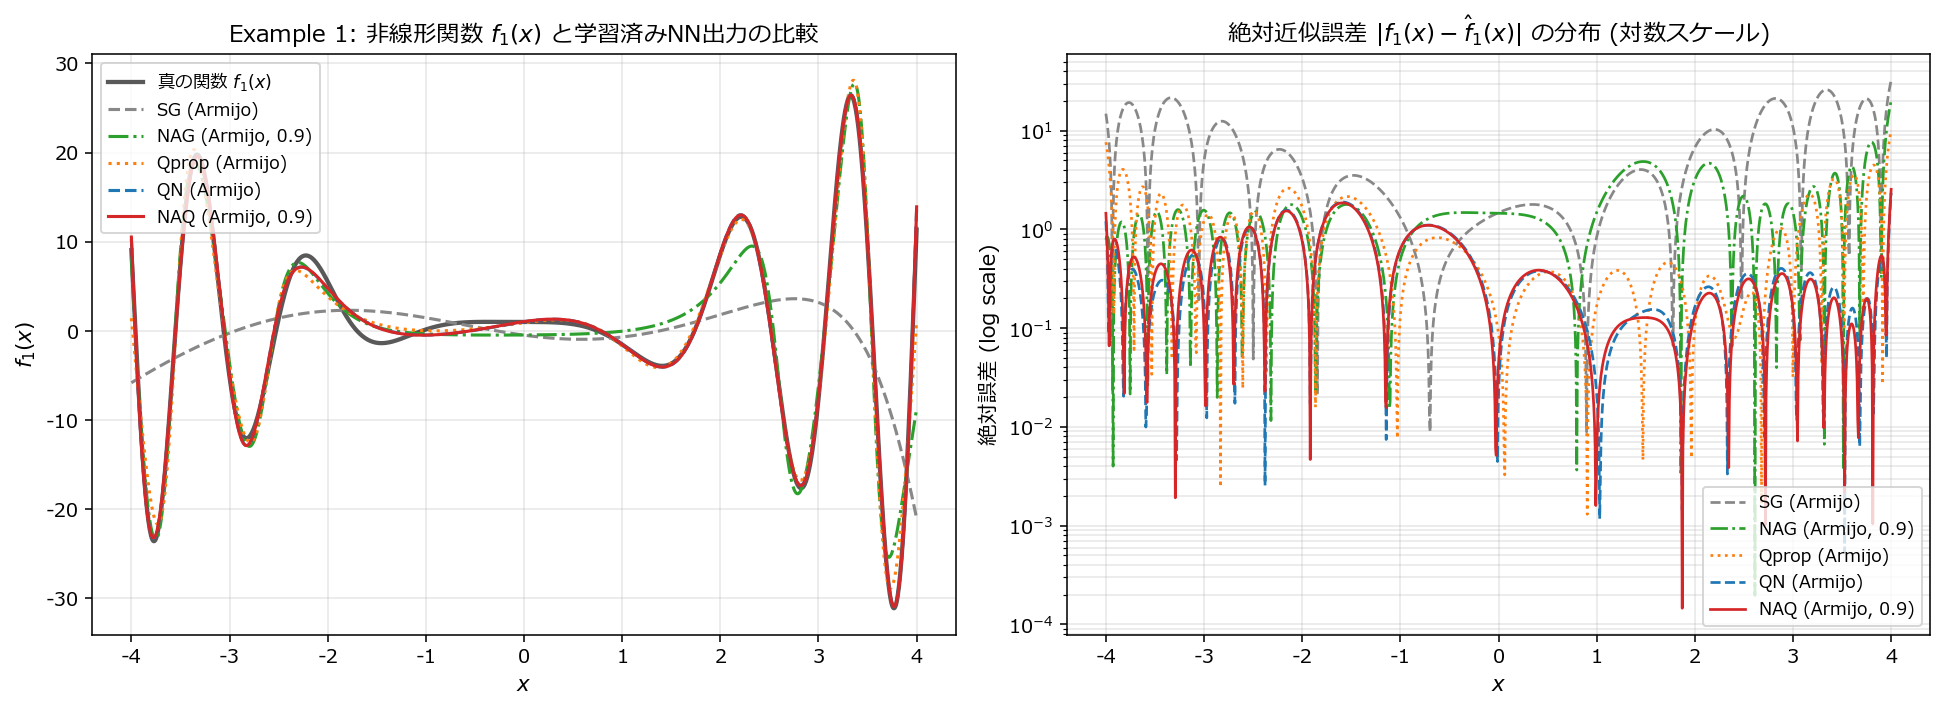

In [4]:
# 1) 関数近似波形と絶対誤差の比較プロット
bmlp = BatchedMLP(n_in=1, n_hid=7, n_out=1)
stats = dataset["norm_stats"]
y_min, y_max = stats["y_min"], stats["y_max"]

x_dense = np.linspace(-4.0, 4.0, 1200)
y_dense_true = 1.0 + (x_dense + 2.0 * x_dense**2) * np.sin(-x_dense**2)
x_dense_norm = 2.0 * (x_dense - stats["x_min"]) / (stats["x_max"] - stats["x_min"]) - 1.0
X_dense_t = torch.tensor(x_dense_norm[:, None], device=device, dtype=torch.float64)

pick_keys = [
    ("SG (Armijo)",      lambda r: r["algo"] == "SG" and r["stepsize"] == "Armijo",   "#888888", "--"),
    ("NAG (Armijo, 0.9)",lambda r: r["algo"] == "NAG" and r["stepsize"] == "Armijo" and r["mu"] == "0.90", "#2ca02c", "-."),
    ("Qprop (Armijo)",   lambda r: r["algo"] == "Qprop",                              "#ff7f0e", ":"),
    ("QN (Armijo)",      lambda r: r["algo"] == "QN",                                 "#1f77b4", "--"),
    ("NAQ (Armijo, 0.9)",lambda r: r["algo"] == "NAQ" and r["mu"] == "0.90",          "#d62728", "-"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# 左: 関数波形
axes[0].plot(x_dense, y_dense_true, color="black", lw=2.2, alpha=0.65, label="真の関数 $f_1(x)$")
for label, cond, color, ls in pick_keys:
    rec = next(r for r in all_results if cond(r))
    with torch.no_grad():
        pred_norm = bmlp.predict(rec["best_weights"].unsqueeze(0), X_dense_t).squeeze().cpu().numpy()
    pred_raw = 0.5 * (pred_norm + 1.0) * (y_max - y_min) + y_min
    axes[0].plot(x_dense, pred_raw, color=color, linestyle=ls, lw=1.6, label=label)
    axes[1].plot(x_dense, np.abs(y_dense_true - pred_raw) + 1e-6, color=color, linestyle=ls, lw=1.4, label=label)

axes[0].set_title("Example 1: 非線形関数 $f_1(x)$ と学習済みNN出力の比較", fontsize=12)
axes[0].set_xlabel("$x$", fontsize=11)
axes[0].set_ylabel("$f_1(x)$", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=9, loc="upper left")

axes[1].set_yscale("log")
axes[1].set_title("絶対近似誤差 $|f_1(x) - \hat{f}_1(x)|$ の分布 (対数スケール)", fontsize=12)
axes[1].set_xlabel("$x$", fontsize=11)
axes[1].set_ylabel("絶対誤差 (log scale)", fontsize=11)
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend(fontsize=9, loc="lower right")

plt.tight_layout()
plt.savefig("../report/img/ex001_function_approx.png", dpi=160, bbox_inches="tight")
plt.show()

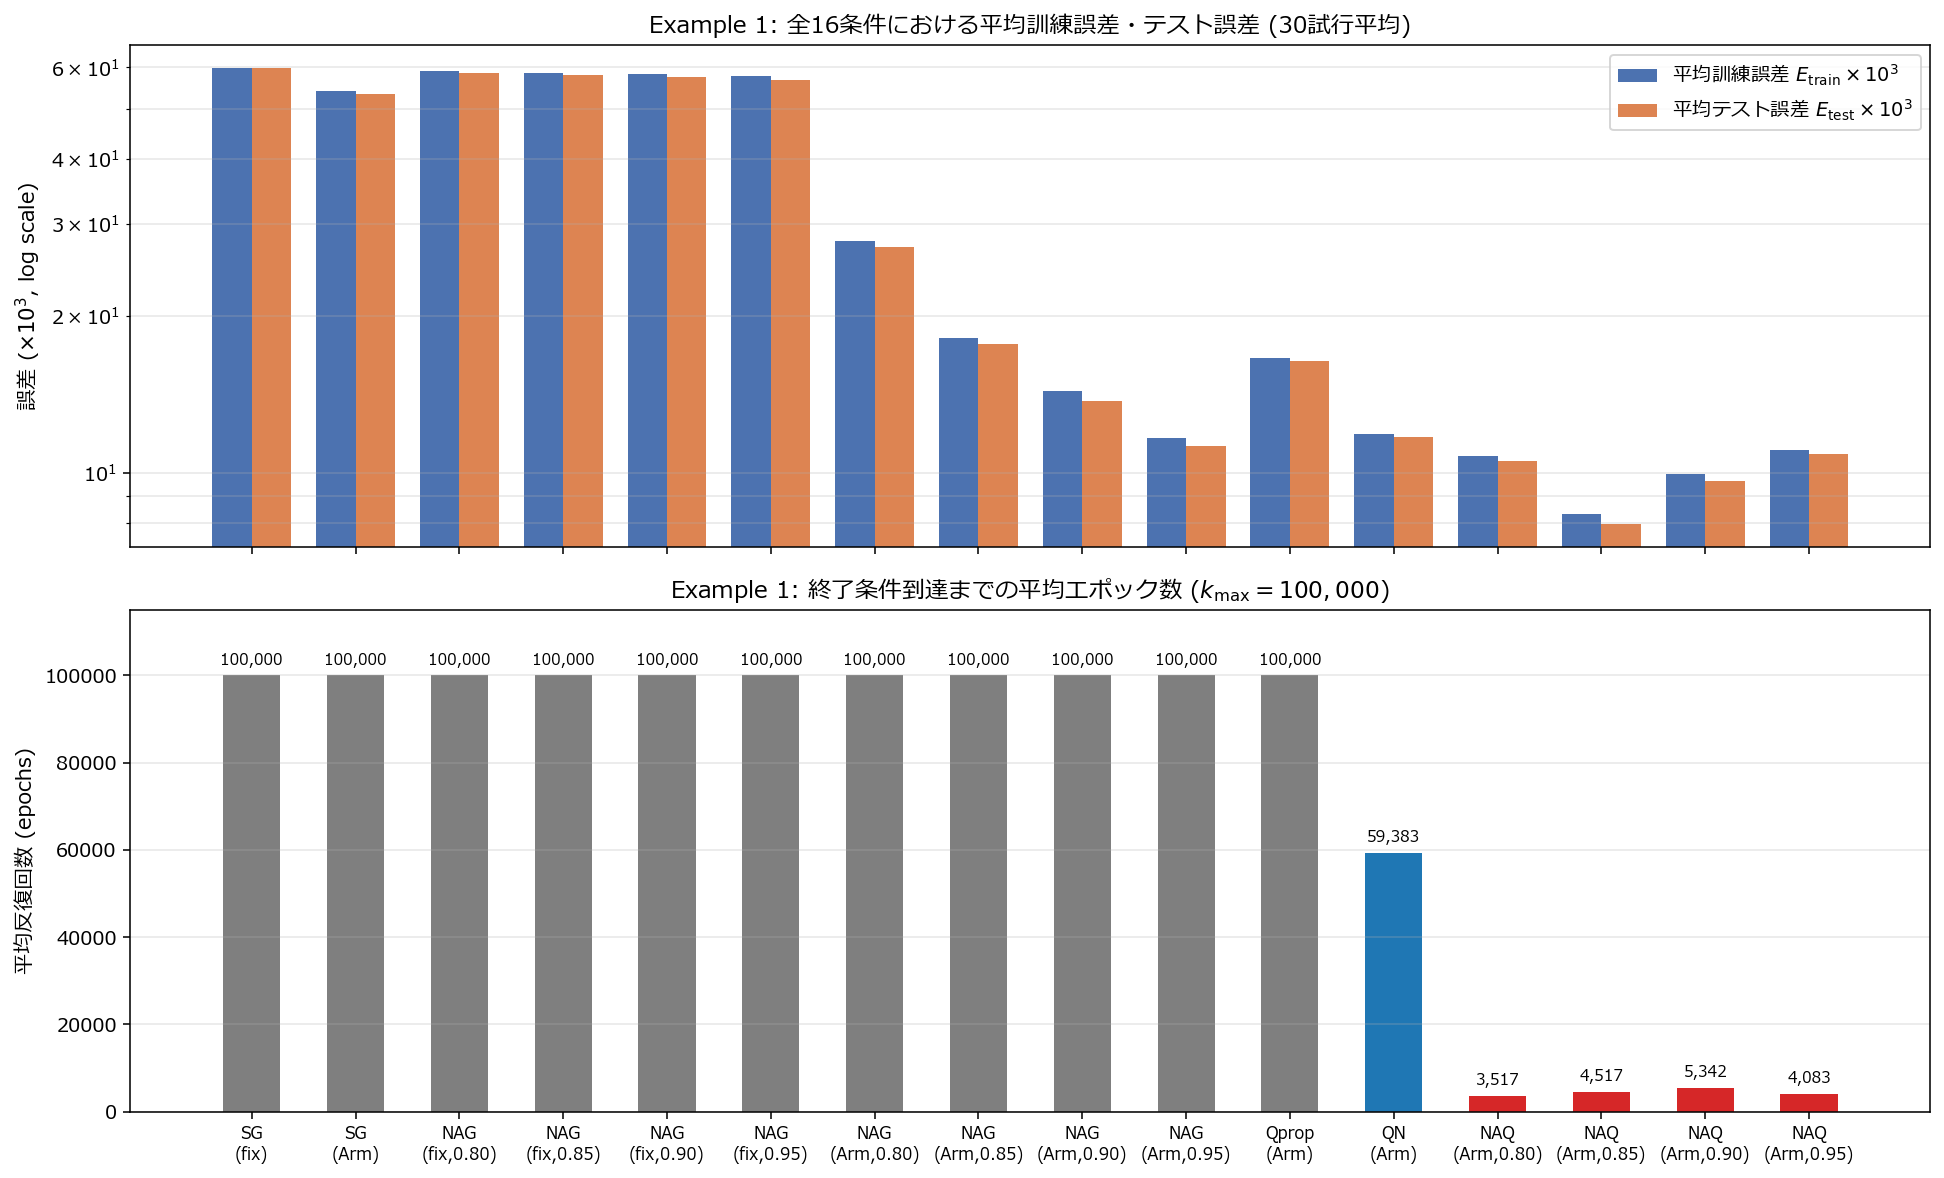

In [5]:
# 2) 全16条件の訓練/テスト誤差および収束エポック数の比較図
labels_16 = [
    f"{r['algo']}\n({r['stepsize'][:3]}" + (f",{r['mu']})" if r["mu"] != "-" else ")")
    for r in all_results
]
tr_aves = [r["train_ave"] for r in all_results]
te_aves = [r["test_ave"] for r in all_results]
epochs_16 = [r["ave_epochs"] for r in all_results]

fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)
x_pos = np.arange(len(all_results))
width = 0.38

axes[0].bar(x_pos - width/2, tr_aves, width, label="平均訓練誤差 $E_{\mathrm{train}} \times 10^3$", color="#4c72b0")
axes[0].bar(x_pos + width/2, te_aves, width, label="平均テスト誤差 $E_{\mathrm{test}} \times 10^3$", color="#dd8452")
axes[0].set_yscale("log")
axes[0].set_ylabel("誤差 ($\times 10^3$, log scale)", fontsize=11)
axes[0].set_title("Example 1: 全16条件における平均訓練誤差・テスト誤差 (30試行平均)", fontsize=12)
axes[0].grid(True, which="both", axis="y", alpha=0.3)
axes[0].legend(fontsize=10)

bar_colors = [
    "#d62728" if r["algo"] == "NAQ" else ("#1f77b4" if r["algo"] == "QN" else "#7f7f7f")
    for r in all_results
]
bars = axes[1].bar(x_pos, epochs_16, width=0.55, color=bar_colors)
for b, ep in zip(bars, epochs_16):
    axes[1].text(b.get_x() + b.get_width()/2, ep + 1800, f"{int(round(ep)):,}", ha="center", va="bottom", fontsize=8)

axes[1].set_ylabel("平均反復回数 (epochs)", fontsize=11)
axes[1].set_ylim(0, 115000)
axes[1].set_title("Example 1: 終了条件到達までの平均エポック数 ($k_{\max}=100,000$)", fontsize=12)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_16, fontsize=8.5)
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../report/img/ex001_algorithm_comparison.png", dpi=160, bbox_inches="tight")
plt.show()